# ENEM: Modelos Lineares 

Este notebook desenvolve e compara modelos de regressão linear (LinearRegression, Ridge e Lasso) para investigar a relação entre características socioeconômicas dos participantes e seu desempenho no ENEM, incluindo uma comparação entre preditores codificados em escalas ordinais e em formato one-hot.

### 0. Configuração Inicial

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from statstech.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from statstech.metrics import root_mean_squared_error

from statstech.model_selection import (
    KFold,
    GridSearchCV,
    cross_val_score
)

from statstech.preprocessing import PolynomialFeatures


from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED
from analysis.io import load_dataset
from analysis.report import save_table
from analysis.config import FIGURES

### 1. Validação

Utilizaremos validação cruzada com 5 folds, embaralhados e reproduzidos através da semente definida anteriormente. O mesmo objeto cv será utilizado na avaliação e comparação de modelos

In [31]:
cv = KFold(5, shuffle=True, random_state=SEED)

### 2. Dados

In [32]:
d = load_dataset("enem")
X_train = d["X_train"]
y_train = d["y_train"]
feature_names = d["feature_names"]

print(f"treino: {X_train.shape[0]} participantes, {X_train.shape[1]} colunas")

treino: 38347 participantes, 41 colunas


### 3. Baseline: média

Antes de avaliar modelos mais complexos, estabelecemos uma baseline que consiste em prever a mesma nota para todos os participantes: a média das notas do conjunto de treinamento.
O desempenho será medido pelo erro quadrático médio, expresso em pontos do ENEM.

In [33]:
baseline_rmse = []
for train_idx, val_idx in cv.split(X_train):

    train_mean = np.mean(y_train[train_idx])

    predictions = np.full(len(val_idx), train_mean)

    rmse = root_mean_squared_error(y_train[val_idx], predictions)

    baseline_rmse.append(rmse)

print(
    f"Baseline RMSE: "
    f"{np.mean(baseline_rmse):.2f} "
    f"+/- {np.std(baseline_rmse):.2f}")

Baseline RMSE: 87.74 +/- 0.54


### 4. Regressão Linear

Agora utilizamos a regressão linear como primeiro modelo treinável, para verificar quanto conseguimos melhorar a previsão em relação à baseline. 
Antes do ajuste, selecionamos as variáveis contínuas que serão padronizadas: tamanho da família, logaritmo da renda per capita e índice de bens.

A padronização é feita em um "Pipeline", garantindo que o escalonador seja ajustado somente com os dados de treinamento de cada fold. 

In [34]:
continues_features_names = ["household_size", "log_income_per_capita", "asset_index_1"]

cols_contiues = [i for i, name in enumerate(feature_names) if name in continues_features_names]

print("Colunas contínuas: ", cols_contiues)

Colunas contínuas:  [8, 9, 40]


In [35]:
linear_model = Pipeline([("scalar", StandardScaler(columns=cols_contiues)),
                         ("model", LinearRegression())])

In [36]:
linear_scores = cross_val_score(linear_model, X_train, y_train, cv=cv, scoring="rmse")

print(f"Regressão Linear RMSE: "
      f"{np.mean(linear_scores):.2f}"
      f" +/-{np.std(linear_scores):.2f}")

Regressão Linear RMSE: 72.87 +/-0.74


A regressão linear obteve RMSE médio de 72,87 pontos (ou uma queda de aproximadamente 16,95%), reduzindo aproximadamente 14,87 pontos. Isso mostra que as variáveis explicativas carregam informações relevantes para a previsão da nota.

Então, iremos ajustar o modelo com todo o conjunto de treinamento para analisar seus coeficientes. Como as variáveis contínuas foram padronizadas, seus coeficientes representam a variação prevista na nota associada a um aumento de um desvio padrão. Para as demais, a interpretação depende da escala e da codificação utilizada

In [37]:
linear_model.fit(X_train, y_train)

linear_coefficients = linear_model.named_steps_["model"].coef_

for name, coefficient in zip(feature_names, linear_coefficients):
    print(f"{name:35s} {coefficient:10.3f}")

father_education                         3.581
father_education_unknown               -10.037
mother_education                         4.331
mother_education_unknown               -19.836
father_occupation                        5.469
father_occupation_unknown              -11.873
mother_occupation                        2.814
mother_occupation_unknown               -6.459
household_size                          -2.680
log_income_per_capita                    9.868
school_3                                43.640
region_Nordeste                         10.991
region_Norte                            -3.858
region_Sudeste                           8.702
region_Sul                              -0.115
sex_M                                   -2.228
race_1                                  17.523
race_2                                  -3.096
race_3                                   2.048
race_4                                   1.865
race_5                                 -23.750
age_group_10 

In [38]:
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": linear_coefficients
})

coefficient_table["abs_coefficient"] = (coefficient_table["coefficient"].abs())

coefficient_table = coefficient_table.sort_values(
    "abs_coefficient",
    ascending = False
)


coefficient_table

,feature,coefficient,abs_coefficient
30,age_group_19,-111.959487,111.959487
29,age_group_18,-79.338762,79.338762
28,age_group_17,-78.048591,78.048591
25,age_group_14,-73.696866,73.696866
24,age_group_13,-62.848092,62.848092
23,age_group_12,-57.471328,57.471328
27,age_group_16,-54.509141,54.509141
22,age_group_11,-53.929266,53.929266
26,age_group_15,-53.812035,53.812035
36,age_group_6,-52.082108,52.082108


### 5. Regressão Ridge 

Utilizaremos o Ridge para acrescentar uma punição para coeficientes demasiadamente grandes, a fim de controlar a complexidade do modelo, especialmente quando existem variáveis correlacionadas.

A intensidade da penalização é controlada pelo hiperparâmetro alhpa: quanto maior este for, maior é a penalização. Para encontrar um valor adequado, testamos uma grade de valores entre 0,01 e 10.000, utilizando GridSearchCV e a mesma validação cruzada de 5 folds, bem como o RMSE como métrica.

In [39]:
ridge_alphas = np.logspace(-2, 4, 13)

ridge_alphas

array([1.00000000e-02, 3.16227766e-02, 1.00000000e-01, 3.16227766e-01,
       1.00000000e+00, 3.16227766e+00, 1.00000000e+01, 3.16227766e+01,
       1.00000000e+02, 3.16227766e+02, 1.00000000e+03, 3.16227766e+03,
       1.00000000e+04])

In [40]:
ridge_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)), ("model", Ridge())])

ridge_search = GridSearchCV(ridge_pipeline, {"model__alpha": ridge_alphas}, cv=cv, scoring="rmse")

In [41]:
ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_)
print("Best RMSE:", ridge_search.best_score_)

Best alpha: {'model__alpha': np.float64(0.31622776601683794)}
Best RMSE: 72.86668456443977


### 6. Regressão Lasso

A regressão Ridge apresentou RMSE de aproximadamente 72,86, e melhor valor alpha de 0.31. Ou seja, a regularização não trouxe melhora significativa.

Agora testaremos a regressão Lasso, que utiliza uma penalização L1, enquanto a anterior trazia uma penalização L2. Diferentemente do Ridge, essa penalização pode levar alguns coeficientes a zero, realizando uma seleção de variáveis.

Para definir uma faixa adequada de valores para alpha, calculamos primeiro o alpha_max, isto é, o valor a partir do qual todos os coeficientes zeram. Em seguida, verificamos essa propriedade ajustando um modelo com esse valor alpha. Essa verificação nos permite construir uma grade de penalizações que abrange desde uma regularização muito forte até regularizações progressimamente menores.

In [42]:
alpha_scaler = StandardScaler(columns=cols_contiues)

alpha_scaler.fit(X_train)

X_scaled = alpha_scaler.transform(X_train)

In [43]:
X_centered = X_scaled - np.mean(X_scaled, axis=0)
y_centered = y_train - np.mean(y_train)

n_samples = X_centered.shape[0]

alpha_max = np.max(np.abs(X_centered.T @ y_centered)) / n_samples

print("Alpha max: ", alpha_max)

Alpha max:  43.99261764567192


In [44]:
lasso_alphas = alpha_max * np.logspace(-6, 0, 19)

lasso_max_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                                ("model", Lasso(alpha=alpha_max))])

lasso_max_pipeline.fit(X_train, y_train)

lasso_max_coefficients = (lasso_max_pipeline.named_steps_["model"].coef_)

print("Maior coeficiente em absoluto:", np.max(np.abs(lasso_max_coefficients)))

print("Todos os coeficientes são zero: ", np.allclose(lasso_max_coefficients, 0))


Maior coeficiente em absoluto: 0.0
Todos os coeficientes são zero:  True


In [45]:
lasso_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                           ("model", Lasso())])

lasso_search = GridSearchCV(lasso_pipeline, {"model__alpha": lasso_alphas}, cv=cv, scoring="rmse")

lasso_search.fit(X_train, y_train)

print("Melhor alpha:", lasso_search.best_params_)
print("Melhor RMSE:", lasso_search.best_score_)

Melhor alpha: {'model__alpha': np.float64(0.0002041956428255474)}
Melhor RMSE: 72.86710274806796


In [46]:
best_lasso = lasso_search.best_estimator_.named_steps_["model"]

print("Iterações:", best_lasso.n_iter_)
print("Iterações máximas:", best_lasso.max_iter)

Iterações: 299
Iterações máximas: 1000


In [47]:
lasso_path_coefficients = [] 
lasso_path_iterations = []

for alpha in lasso_alphas:

    model = Pipeline([("scaler", StandardScaler(columns=cols_contiues)),
                      ("model", Lasso(alpha=alpha))])

    model.fit(X_train, y_train)

    fitted_lasso = model.named_steps_["model"]

    lasso_path_coefficients.append(fitted_lasso.coef_)

    lasso_path_iterations.append(fitted_lasso.n_iter_)

lasso_path_coefficients = np.array(lasso_path_coefficients)

print("Formato da matriz de coeficientes", lasso_path_coefficients.shape)
print("Máximo de iterações", max(lasso_path_iterations))




Formato da matriz de coeficientes (19, 41)
Máximo de iterações 300


O Lasso obteve RMSE médio de 72,87 pontos, praticamente igual ao da regressão linear. Portanto, a penalização L1 não trouxe uma melhora relevante para a previsão das notas.

O GridSearchCV selecionou um alpha de aproximadamente 0,000204, dentro da grade de valores testada. O ajuste desse modelo terminou em 299 iterações, abaixo do limite máximo de 1.000.

Em seguida, analisaremos a trajetória dos coeficientes para observar como a intensidade da penalização altera os pesos atribuídos às variáveis.

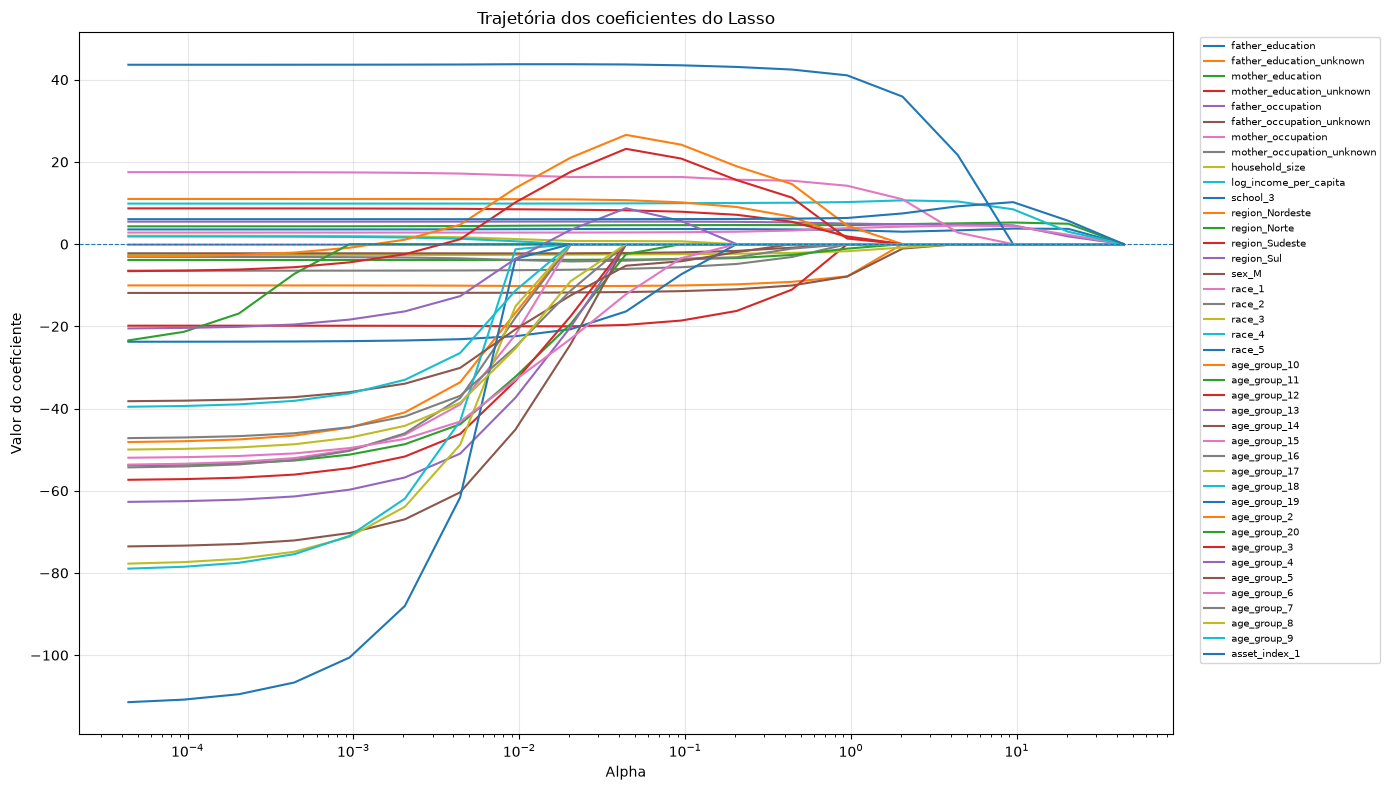

In [48]:
fig, ax = plt.subplots(figsize=(14, 8))

for i, feature in enumerate(feature_names):
    ax.plot(lasso_alphas,
            lasso_path_coefficients[:, i],
            label=feature)

ax.set_xscale("log")
ax.axhline(0, linewidth=0.8, linestyle="--")

ax.set_xlabel("Alpha")
ax.set_ylabel("Valor do coeficiente")
ax.set_title("Trajetória dos coeficientes do Lasso")

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

ax.grid(alpha=0.3)
fig.tight_layout()

plt.show()

**A trajetória mostra que à medida que o alpha aumenta, a penalização L1 reduz progressivamente a magnitude dos coeficientes, como esperado**

**Para valores suficientemente grandes de alpha, os coeficientes chegam a zero, como discutido anteriormente**

In [49]:
FIGURES.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES / "enem_lasso_caminho.png",
    dpi=200,
    bbox_inches="tight" 
)

### 7. Comparação entre codificação ordinal e one-hot

Até aqui, utilizamos a codificação ordinal das variáveis categóricas. Entretanto, essa representação atribui valores numéricos às categorias e pode introduzir uma relação de ordem que não existe necessariamente entre elas. Para avaliar o efeito de tal escolha, vamos repetir o Ridge utilizando a codificação one-hot, que representa cada categoria por uma variável binária. 

Evidentemente, manteremos o mesmo conjunto de alvo, a mesma validação cruzada e a mesma grade de alphas, para comparar o desempenho das duas representações com maior controle.

In [50]:
dataset_onehot = load_dataset("enem_onehot")

X_train_onehot = dataset_onehot["X_train"]
y_train_onehot = dataset_onehot["y_train"]

feature_names_onehot = dataset_onehot["feature_names"]

print("Formato dos preditores:", X_train_onehot.shape)
print("Formato dos alvos", y_train_onehot.shape)
print("Mesmos alvos do conjunto ordinal:", np.array_equal(y_train, y_train_onehot))

Formato dos preditores: (38347, 66)
Formato dos alvos (38347,)
Mesmos alvos do conjunto ordinal: True


In [51]:
cols_contiues_onehot = [i for i, name in enumerate(feature_names_onehot) if name in continues_features_names]
print("Colunas contínuas:", cols_contiues_onehot)

Colunas contínuas: [4, 65]


In [52]:
ridge_onehot_pipeline = Pipeline([
    ("scaler", StandardScaler(columns=cols_contiues_onehot)),
    ("model", Ridge())
])

ridge_onehot_search = GridSearchCV(
    ridge_onehot_pipeline,
    {"model__alpha": ridge_alphas},
    cv=cv,
    scoring="rmse"
)


In [53]:
ridge_onehot_search.fit(X_train_onehot, y_train_onehot)


print("Melhor alpha:", ridge_onehot_search.best_params_)

print("Melhor RMSE:", ridge_onehot_search.best_score_)

Melhor alpha: {'model__alpha': np.float64(0.31622776601683794)}
Melhor RMSE: 72.475243691309


In [54]:
ordinal_results = ridge_search.cv_results_[ridge_search.best_index_]

onehot_results = ridge_onehot_search.cv_results_[ridge_onehot_search.best_index_]

encoding_comparison = pd.DataFrame([
    {
        "Codificação": "Original",
        "Melhor alpha": ridge_search.best_params_["model__alpha"],
        "RMSE médio": ridge_search.best_score_,
        "Desvio médio entre os folds": ordinal_results["std_score"]
    },
    {
        "Codificação": "One-hot",
        "Melhor alpha": ridge_onehot_search.best_params_["model__alpha"],
        "RMSE médio": ridge_onehot_search.best_score_,
        "Desvio médio entre os folds": onehot_results["std_score"]
    }
])

encoding_comparison

,Codificação,Melhor alpha,RMSE médio,Desvio médio entre os folds
0,Original,0.316228,72.866685,0.825659
1,One-hot,0.316228,72.475244,0.783703


**O modelo Ridge com codificação one-hot obteve RMSE médio de 72,48, inferior aos 72,87 pontos obtidos com a codificação ordinal. Ambos os modelos selecionaram o mesmo valor de alpha, o que permite observar a diferença de desempenho associada às representações utilizadas.**

**A seguir, reuniremos os resultados obtidos pelos dois modelos em uma tabela e examinaremos o desempenho em cada fold da validação cruzada, verificando se a vantagem da codificação one-hot se mantém nas diferentes partições dos dados.**

In [55]:
folding_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "Ordinal": ordinal_results["scores"],
    "One-hot": onehot_results["scores"]
})

folding_comparison["Diferença"] = (
    folding_comparison["Ordinal"] - folding_comparison["One-hot"]
)

folding_comparison

,Fold,Ordinal,One-hot,Diferença
0,1,74.265104,73.794019,0.471085
1,2,72.277906,72.021345,0.256561
2,3,72.909589,72.554688,0.354901
3,4,72.268140,71.830762,0.437377
4,5,72.612684,72.175404,0.437280


### 8. Conclusão

A comparação por fold confirma a vantagem da codificação one-hot, visto que ela apresentou RMSE inferior ao da codificação ordinal em todos os folds. A redução média foi de 0,39 pontos, que apesar de ser pequena, foi consistente entre os folds.

Considerando os modelos avaliados, o Ridge ordinal e o Lasso apresentaram desempenhos praticamente iguais, com RMSE próximo de 72,87 pontos. Portanto, as regularizações L1 e L2 não trouxeram melhorias relevantes nesse cenário. O melhor resultado obtido foi o do one-hot, que alcançou RMSE de 72,48 pontos.

Assim, entre os modelos lineares avaliados, o Ridge com codificação one-hot apresentou melhor desempenho. 

# ENEM: Polinomial

Nesta etapa, investigaremos se a relação entre as características socioeconômicas dos participantes e suas notas no ENEM pode ser representada por relações não lineares.

Para isso, adicionaremos atributos polinomiais de segundo grau sobre três variáveis: renda per capita, índices de bens e escolaridade da mãe. Também construiremos manualmente um termo de interação entre renda per capita e escola privada, permitindo investigar se a relação entre renda e desempenho varia conforme o tipo de escola.

Utilizaremos o modelo Ridge sobre a matriz de atributos ampliada, mantendo a mesma grade de hiperparâmetros e o mesmo esquema de validação cruzada empregado anteriormente.

Por fim, iremos comparar o RMSE obtido pelo Ridge convencional, verificando se tal inclusão gera ganho preditivo relevante.

In [58]:
feature_names = feature_names.tolist()

poly_feature_names = ["log_income_per_capita", "asset_index_1", "mother_education"]

cols_poly = [feature_names.index(name) for name in poly_feature_names]

col_income = feature_names.index("log_income_per_capita")
col_priv = feature_names.index("school_3") #checar se tá certo

print("Colunas polinomias", cols_poly)
print("Colunas de renda", col_income)
print("Colunas de escola privada", col_priv)

Colunas polinomias [9, 40, 2]
Colunas de renda 9
Colunas de escola privada 10


In [62]:
poly = PolynomialFeatures(degree=2)

Z_train = poly.fit_transform(X_train[:, cols_poly])

inter = (X_train[:, [col_income]] * X_train[:, [col_priv]])

X_aug = np.hstack([X_train, Z_train, inter])


print("Matriz original:", X_train.shape)
print("Atributos polinomiais:", Z_train.shape)
print("Interação:", inter.shape)
print("Matriz aumentada:", X_aug.shape)

Matriz original: (38347, 41)
Atributos polinomiais: (38347, 9)
Interação: (38347, 1)
Matriz aumentada: (38347, 51)


In [65]:
start_poly = X_train.shape[1]
end_poly = start_poly + Z_train.shape[1]

cols_scale_aug = sorted(set(cols_contiues + cols_poly + list(range(start_poly, end_poly)) + [end_poly]))

ridge_poly_pipeline = Pipeline([("scaler", StandardScaler(columns=cols_scale_aug)),
                                ("model", Ridge())])

ridge_poly_search = GridSearchCV(ridge_poly_pipeline, {"model__alpha":ridge_alphas},cv=cv, scoring="rmse")

ridge_poly_search.fit(X_aug, y_train)

print("Melhor alpha:", ridge_poly_search.best_params_)
print("Melhor RMSE:", ridge_poly_search.best_score_)

Melhor alpha: {'model__alpha': np.float64(0.31622776601683794)}
Melhor RMSE: 72.50576086658778


In [66]:
poly_results = ridge_poly_search.cv_results_[ridge_poly_search.best_index_]

e7_comparison = pd.DataFrame([
    {
        "Modelo": "Ridge ordinal",
        "RMSE": ridge_search.best_score_,
        "Desvio": ridge_search.cv_results_[ridge_search.best_index_]["std_score"]
    },
    {
        "Modelo": "Ridge one-hot",
        "RMSE": ridge_onehot_search.best_score_,
        "Desvio": ridge_onehot_search.cv_results_[ridge_onehot_search.best_index_]["std_score"]
    },
    {
        "Modelo": "Ridge polinomial",
        "RMSE": ridge_poly_search.best_score_,
        "Desvio": poly_results["std_score"]
    },
])

print(e7_comparison)

             Modelo       RMSE    Desvio
0     Ridge ordinal  72.866685  0.825659
1     Ridge one-hot  72.475244  0.783703
2  Ridge polinomial  72.505761  0.787962


In [68]:
ordinal_scores = ridge_search.cv_results_[ridge_search.best_index_]["scores"]

onehot_scores = ridge_onehot_search.cv_results_[ridge_onehot_search.best_index_]["scores"]

poly_scores = ridge_poly_search.cv_results_[ridge_poly_search.best_index_]["scores"]

e7_fold_comparison = pd.DataFrame({
    "Fold": range(1,6),
    "Ridge ordinal": ordinal_scores,
    "Ridge one-hot": onehot_scores,
    "Ridge polinomial": poly_scores
})

save_table(e7_comparison.to_dict(orient="records"), "enem_ridge_polinomial")

WindowsPath('C:/Users/lucas/statstech-analise/results/tables/enem_ridge_polinomial.csv')

### Conclusão 

A inclusão de atributos polinomiais de segundo grau e da interação entre renda per capita e escola privada diminuiu o RMSE de 72,87 para 72,51 pontos em relação ao original. Contudo, o Ridge one-hot ainda apresentou RMSE ligeiramente menor que o Ridge polinomial.

Logo, a expansão polinomial não demonstrou ganho preditivo significativo neste experimento.